In [1]:
import numpy as np
import matplotlib.pyplot as plt

R = 8.314
F = 96485

target_J = np.array([0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2])
target_V = np.array([0.98, 0.91, 0.86, 0.82, 0.79, 0.76, 0.73, 0.70, 0.66, 0.62, 0.57, 0.51, 0.43])

def sofc_voltage(J, params, T=1073, P_H2=0.87, P_O2=0.21, P_H2O=0.13):
    """
    Computes SOFC terminal voltage for a given current density J and parameters.
    Parameters to optimize:
    - params[0]: E_0 (Standard potential / Reference Nernst, V)
    - params[1]: alpha (Charge transfer coefficient)
    - params[2]: r (Ohmic resistance, ohm cm^2)
    - params[3]: J_L (Limiting current density, A/cm^2)
    """
    E_0, alpha, r, J_L = params

    E_nernst = E_0 + (R * T / (2 * F)) * np.log((P_H2 * (P_O2**0.5)) / P_H2O)

    alpha = max(1e-3, alpha)
    J_L = max(J.max() + 0.01, J_L)

    eta_act = (R * T / (alpha * F)) * np.log(np.maximum(1, J * 1000))

    eta_ohm = J * r

    eta_conc = - (R * T / (2 * F)) * np.log(1 - (J / J_L))

    V = E_nernst - eta_act - eta_ohm - eta_conc
    return np.clip(V, 0, 1.5)

def objective_function(params):
    """Calculates Sum of Squared Errors (SSE) between model and target experimental values."""
    pred_V = sofc_voltage(target_J, params)
    sse = np.sum((target_V - pred_V) ** 2)
    return sse

In [2]:
def grey_wolf_optimizer(obj_func, bounds, num_wolves=30, max_iter=100):
    dim = len(bounds)
    lb = np.array([b[0] for b in bounds])
    ub = np.array([b[1] for b in bounds])

    Alpha_pos = np.zeros(dim)
    Alpha_score = float("inf")

    Beta_pos = np.zeros(dim)
    Beta_score = float("inf")

    Delta_pos = np.zeros(dim)
    Delta_score = float("inf")

    Positions = np.random.uniform(low=lb, high=ub, size=(num_wolves, dim))

    convergence_curve = []

    for l in range(max_iter):
        for i in range(num_wolves):
            Positions[i] = np.clip(Positions[i], lb, ub)

            fitness = obj_func(Positions[i])

            if fitness < Alpha_score:
                Alpha_score = fitness
                Alpha_pos = Positions[i].copy()

            if fitness > Alpha_score and fitness < Beta_score:
                Beta_score = fitness
                Beta_pos = Positions[i].copy()

            if fitness > Alpha_score and fitness > Beta_score and fitness < Delta_score:
                Delta_score = fitness
                Delta_pos = Positions[i].copy()

        a = 2 - l * (2 / max_iter)

        for i in range(num_wolves):
            for j in range(dim):

                r1, r2 = np.random.rand(), np.random.rand()
                A1 = 2 * a * r1 - a
                C1 = 2 * r2
                D_alpha = abs(C1 * Alpha_pos[j] - Positions[i, j])
                X1 = Alpha_pos[j] - A1 * D_alpha

                r1, r2 = np.random.rand(), np.random.rand()
                A2 = 2 * a * r1 - a
                C2 = 2 * r2
                D_beta = abs(C2 * Beta_pos[j] - Positions[i, j])
                X2 = Beta_pos[j] - A2 * D_beta

                r1, r2 = np.random.rand(), np.random.rand()
                A3 = 2 * a * r1 - a
                C3 = 2 * r2
                D_delta = abs(C3 * Delta_pos[j] - Positions[i, j])
                X3 = Delta_pos[j] - A3 * D_delta

                Positions[i, j] = (X1 + X2 + X3) / 3

        convergence_curve.append(Alpha_score)

    return Alpha_pos, Alpha_score, convergence_curve

--- Optimization Results ---
Estimated E_0 (Reference potential): 1.3293 V
Estimated Alpha (Transfer Coefficient): 0.9000
Estimated r (Ohmic Resistance): 0.0110 Ohm cm^2
Estimated J_L (Limiting Current Density): 1.2500 A/cm^2
Minimum SSE: 0.043521


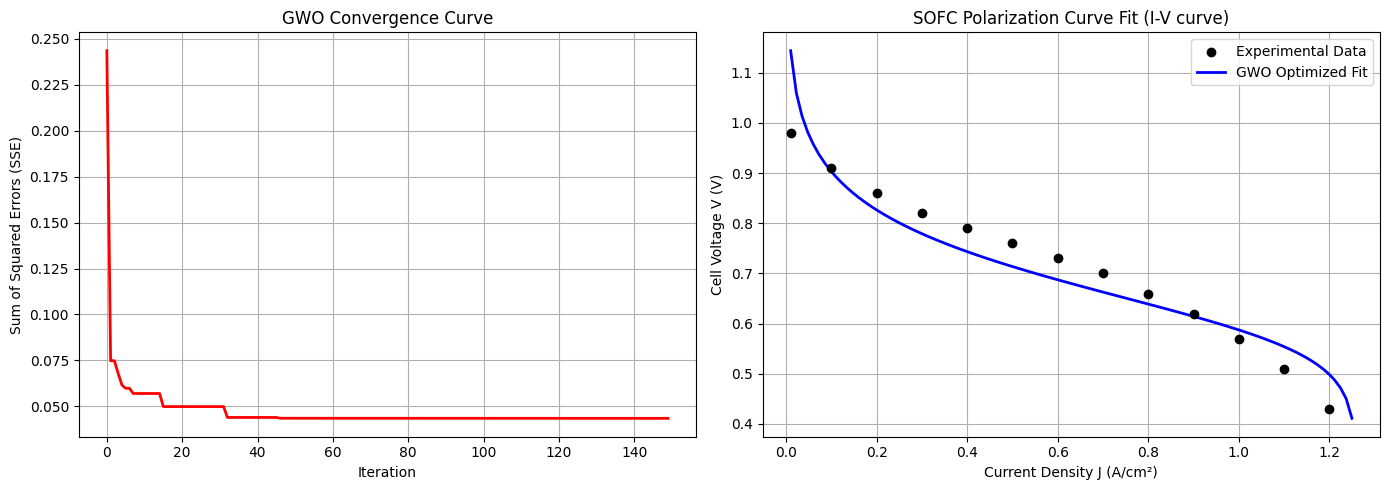

In [3]:
bounds = [
    (0.8, 1.4),
    (0.1, 0.9),
    (0.01, 0.5),
    (1.25, 2.0)
]

best_params, best_score, convergence = grey_wolf_optimizer(
    objective_function, bounds, num_wolves=40, max_iter=150
)

print("--- Optimization Results ---")
print(f"Estimated E_0 (Reference potential): {best_params[0]:.4f} V")
print(f"Estimated Alpha (Transfer Coefficient): {best_params[1]:.4f}")
print(f"Estimated r (Ohmic Resistance): {best_params[2]:.4f} Ohm cm^2")
print(f"Estimated J_L (Limiting Current Density): {best_params[3]:.4f} A/cm^2")
print(f"Minimum SSE: {best_score:.6f}")

fine_J = np.linspace(0.01, 1.25, 100)
optimized_V = sofc_voltage(fine_J, best_params)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(convergence, color='red', linewidth=2)
ax1.set_title("GWO Convergence Curve")
ax1.set_xlabel("Iteration")
ax1.set_ylabel("Sum of Squared Errors (SSE)")
ax1.grid(True)

ax2.scatter(target_J, target_V, color='black', label='Experimental Data', zorder=5)
ax2.plot(fine_J, optimized_V, color='blue', label='GWO Optimized Fit', linewidth=2)
ax2.set_title("SOFC Polarization Curve Fit (I-V curve)")
ax2.set_xlabel("Current Density J (A/cm²)")
ax2.set_ylabel("Cell Voltage V (V)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()